# Experiment 5

This Experiment is a way to test how much structural Information is contained in the hidden representations. By using the pretrained representations and building simplistic linear heads on top we cann see how much Info is contained in these hidden representations.

First step is to define the Linear head models. 

1. Secondary Structure: Linear Layer trained via Crossentropy 
2. Tertiary Structure: 2 Linear Projections combined via Dot product

In [1]:
#!pip install fair-esm tqdm matplotlib scikit-learn

## Import packages

In [2]:
import os, torch, gc, copy
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from tqdm.notebook import tqdm
from IPython.utils import io
import numpy as np
import random
from sklearn.metrics import accuracy_score


In [3]:
import esm
import sys
print(sys.executable)
print(esm.__file__)

from esm.data import ESMStructuralSplitDataset
import matplotlib.pyplot as plt


/dss/dsshome1/04/ra58seq2/unsupervised-learning-in-biology/.venv/bin/python
/dss/dsshome1/04/ra58seq2/unsupervised-learning-in-biology/.venv/lib/python3.12/site-packages/esm/__init__.py


## Konfig

In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE_EXTRACT = 1 
BATCH_SIZE_TRAIN = 4  
LR = 1e-4
NUM_EPOCHS = 5 
LEVELS = ['family'] 

def set_seed(seed=42):
    """Sets the seed for reproducibility across all libraries."""
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # If you are using multi-GPU.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

# Set the seed
SEED = 42
set_seed(SEED)
print(f"Random seed set to {SEED}")

Random seed set to 42


In [5]:
print(f"Using device: {DEVICE}")

Using device: cuda


In [6]:
def clear_memory():
    """VRAM und RAM leeren, zwischen den evaluations"""
    gc.collect()
    torch.cuda.empty_cache()
    if torch.cuda.is_available():
        torch.cuda.synchronize()

clear_memory()


## Define the model heads which are later trained

In [7]:
class LinearProbeSSP(nn.Module):
    def __init__(self, input_dim, num_classes=8):
        super().__init__()
        self.proj = nn.Linear(input_dim, num_classes)
    def forward(self, x): return self.proj(x)

class LinearContactProbe(nn.Module):
    def __init__(self, input_dim, projection_dim=128):
        super().__init__()
        self.proj1 = nn.Linear(input_dim, projection_dim)
        self.proj2 = nn.Linear(input_dim, projection_dim)

    def forward(self, x):
        z1, z2 = self.proj1(x), self.proj2(x)
        logits = torch.bmm(z1, z2.transpose(1, 2))
        return logits  # Direktes Skalarprodukt laut Paper


## Define Precision at l metric

In [8]:

def compute_precision_at_l(logits, labels, seq_len):
    if seq_len < 24: return 0.0
    valid_logits = logits[1:seq_len+1, 1:seq_len+1]
    valid_labels = labels[1:seq_len+1, 1:seq_len+1]
    l = valid_logits.shape[0]
    idx = torch.arange(l, device=logits.device)
    i, j = torch.meshgrid(idx, idx, indexing='ij')
    mask = torch.abs(i - j) >= 24
    masked_logits, masked_labels = valid_logits[mask], valid_labels[mask]
    if masked_labels.numel() == 0: return 0.0
    _, top_indices = torch.topk(masked_logits, min(l, masked_logits.numel()))
    return (masked_labels[top_indices].sum() / min(l, masked_logits.numel())).item()


### Caching & Collator

In [9]:
class UnifiedCollator:
    def __init__(self, alphabet):
        self.alphabet = alphabet
        self.batch_converter = alphabet.get_batch_converter()
        self.ss8_map = {'H':0, 'E':1, 'T':2, 'S':3, 'G':4, 'B':5, 'I':6, '-':7, 'C':7}
    def __call__(self, batch):
        batch = [item for item in batch if item is not None]
        _, _, tokens = self.batch_converter([(str(i), item['seq']) for i, item in enumerate(batch)])
        max_len = tokens.size(1)
        ssp_labels, contact_maps = [], []
        for item in batch:
            ssp_str = item.get('ssp') or item.get('label')
            indices = [-100] + [self.ss8_map.get(c, 7) for c in ssp_str] + [-100]
            ssp_labels.append(torch.tensor(indices[:max_len] + [-100]*(max_len-len(indices[:max_len]))))
            c_map = np.full((max_len, max_len), -1.0, dtype=np.float32)
            c_map[1:len(item['seq'])+1, 1:len(item['seq'])+1] = (item['dist'] < 8.0).astype(np.float32)
            contact_maps.append(torch.from_numpy(c_map))
        return {'input_ids': tokens, 'labels': torch.stack(ssp_labels), 'contacts': torch.stack(contact_maps)}


### Training Loop

In [10]:
model_names = [#'random_34',
               #'esm1_t6_43M_UR50S',
               #'esm1_t12_85M_UR50S', 
               'esm1_t34_670M_UR50S',
               #'esm1_t34_670M_UR50D',
               #'esm1_t34_670M_UR100',
               #'esm1b_t33_650M_UR50S'
               ] 
# %% [markdown]
# ### Memory-Efficient Training Loop (5-Fold Cross Validation)
# Durchführung einer 5-fachen Kreuzvalidierung gemäß Paper-Methodik [cite: 271, 801]

# Ergebnisse werden hierarchisch gespeichert: [Modell][Level][Partition]
ssp_results = {}
contact_results = {}

PARTITIONS = ['0', '1', '2', '3', '4'] # Die 5 im Paper verwendeten Partitionen [cite: 271, 969]

for name in model_names:
    print(f"\n{'='*40}\nSTARTING MODEL: {name}\n{'='*40}")
    
    # 1. Modell laden (einmalig pro Modell-Typ)
    if name == 'random_34':
        model, alphabet = esm.pretrained.esm1_t34_670M_UR50S()
        for p in model.parameters():
            if p.dim() > 1: torch.nn.init.xavier_uniform_(p)
            else: torch.nn.init.constant_(p, 0)
    else:
        model, alphabet = getattr(esm.pretrained, name)()
    
    model = model.to(DEVICE).eval()
    EMBED_DIM, LAYER_IDX = model.args.embed_dim, model.num_layers
    
    ssp_results[name] = {lvl: [] for lvl in LEVELS}
    contact_results[name] = {lvl: [] for lvl in LEVELS}

    for lvl in LEVELS:
        print(f"\n--- Testing Level: {lvl} ---")
        
        for part in PARTITIONS:
            print(f"Partition {part}/4...")
            
            # Datensätze für die aktuelle Partition laden [cite: 798, 970]
            collator = UnifiedCollator(alphabet)
            
            with io.capture_output() as captured:
                train_ds = ESMStructuralSplitDataset(
                    split_level=lvl, 
                    cv_partition=part, 
                    split='train', 
                    root_path='./data', 
                    download=True
                )
                valid_ds = ESMStructuralSplitDataset(
                    split_level=lvl, 
                    cv_partition=part, 
                    split='valid', 
                    root_path='./data', 
                    download=True
                )
            
            train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE_EXTRACT, collate_fn=collator, shuffle=True)
            valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE_EXTRACT, collate_fn=collator)

            # 2. Probes für jede Partition neu initialisieren
            probe_ssp = LinearProbeSSP(EMBED_DIM).to(DEVICE)
            probe_c = LinearContactProbe(EMBED_DIM).to(DEVICE)
            
            # Optimizer mit Weight Decay 0.2 für Kontakte [cite: 997]
            optimizer = optim.AdamW([
                {'params': probe_ssp.parameters(), 'weight_decay': 0.0}, 
                {'params': probe_c.parameters(), 'weight_decay': 0.2}    
            ], lr=LR)

            # 3. Training
            for epoch in range(NUM_EPOCHS):
                probe_ssp.train(); probe_c.train()
                
                # HIER: tqdm für die Batch-Schleife hinzugefügt
                train_pbar = tqdm(train_loader, desc=f"Model: {name} | Part: {part} | Epoch {epoch+1}/{NUM_EPOCHS}", leave=False, disable=True)
                
                for batch in train_pbar:
                    tokens = batch['input_ids'].to(DEVICE)
                    with torch.no_grad():
                        results = model(tokens, repr_layers=[LAYER_IDX])
                        reprs = results["representations"][LAYER_IDX]
                    
                    optimizer.zero_grad()
                    logits_ssp = probe_ssp(reprs)
                    loss_ssp = nn.CrossEntropyLoss(ignore_index=-100)(logits_ssp.view(-1, 8), batch['labels'].to(DEVICE).view(-1))
                    
                    logits_c = probe_c(reprs)
                    c_targets = batch['contacts'].to(DEVICE)
                    mask_c = c_targets != -1
                    loss_c = nn.BCEWithLogitsLoss()(logits_c[mask_c], c_targets[mask_c])
                    
                    (loss_ssp + loss_c).backward()
                    optimizer.step()
                    
                    # Fortschrittsanzeige mit aktuellen Verlustwerten aktualisieren
                    train_pbar.set_postfix({"SSP_Loss": f"{loss_ssp.item():.4f}", "Cont_Loss": f"{loss_c.item():.4f}"})

            # 4. Finale Validierung dieser Partition
            probe_ssp.eval(); probe_c.eval()
            part_acc, part_prec, count = 0, 0, 0
            
            # HIER: tqdm auch für die Validierung (hilfreich bei großen Datensätzen)
            val_pbar = tqdm(valid_loader, desc=f"Validating Partition {part}", leave=False, disable=True)
            
            with torch.no_grad():
                for batch in val_pbar:
                    tokens = batch['input_ids'].to(DEVICE)
                    results = model(tokens, repr_layers=[LAYER_IDX])
                    reprs = results["representations"][LAYER_IDX]
                    
                    # SSP Accuracy (Q8) [cite: 279, 342]
                    preds = torch.argmax(probe_ssp(reprs), dim=-1).cpu()
                    mask = batch['labels'] != -100
                    part_acc += accuracy_score(batch['labels'][mask], preds[mask])
                    
                    # Long-range Precision (Top-L) [cite: 279, 342]
                    val_logits = probe_c(reprs)
                    lengths = (tokens != model.padding_idx).sum(1).cpu() - 2
                    precs = [compute_precision_at_l(val_logits[j], batch['contacts'][j].to(DEVICE), lengths[j]) for j in range(len(tokens))]
                    part_prec += np.mean(precs)
                    count += 1
            
            # Ergebnisse der Partition speichern
            ssp_results[name][lvl].append(part_acc / count)
            contact_results[name][lvl].append(part_prec / count)
            print(f"Partition {part} End: SSP {ssp_results[name][lvl][-1]:.3f}, Cont {contact_results[name][lvl][-1]:.3f}")

    # Speicherbereinigung
    del model, probe_ssp, probe_c
    clear_memory()

# %% [markdown]
# ## Finale Auswertung (Mean ± SD)
# Berechnung der finalen Metriken wie in Tabelle 3 des Papers [cite: 340, 801]

for name in model_names:
    print(f"\nFinal Results for {name}:")
    for lvl in LEVELS:
        ssp_mean = np.mean(ssp_results[name][lvl])
        ssp_std = np.std(ssp_results[name][lvl])
        cont_mean = np.mean(contact_results[name][lvl])
        cont_std = np.std(contact_results[name][lvl])
        print(f"  {lvl:12} | SSP Acc: {ssp_mean:.1%} ± {ssp_std:.2f} | Cont Prec: {cont_mean:.1%} ± {cont_std:.2f}")


STARTING MODEL: esm1_t34_670M_UR50S



--- Testing Level: family ---
Partition 0/4...


Partition 0 End: SSP 0.696, Cont 0.338
Partition 1/4...


Partition 1 End: SSP 0.685, Cont 0.298
Partition 2/4...


Partition 2 End: SSP 0.692, Cont 0.301
Partition 3/4...


Partition 3 End: SSP 0.689, Cont 0.293
Partition 4/4...


Partition 4 End: SSP 0.680, Cont 0.299



Final Results for esm1_t34_670M_UR50S:
  family       | SSP Acc: 68.8% ± 0.01 | Cont Prec: 30.6% ± 0.02


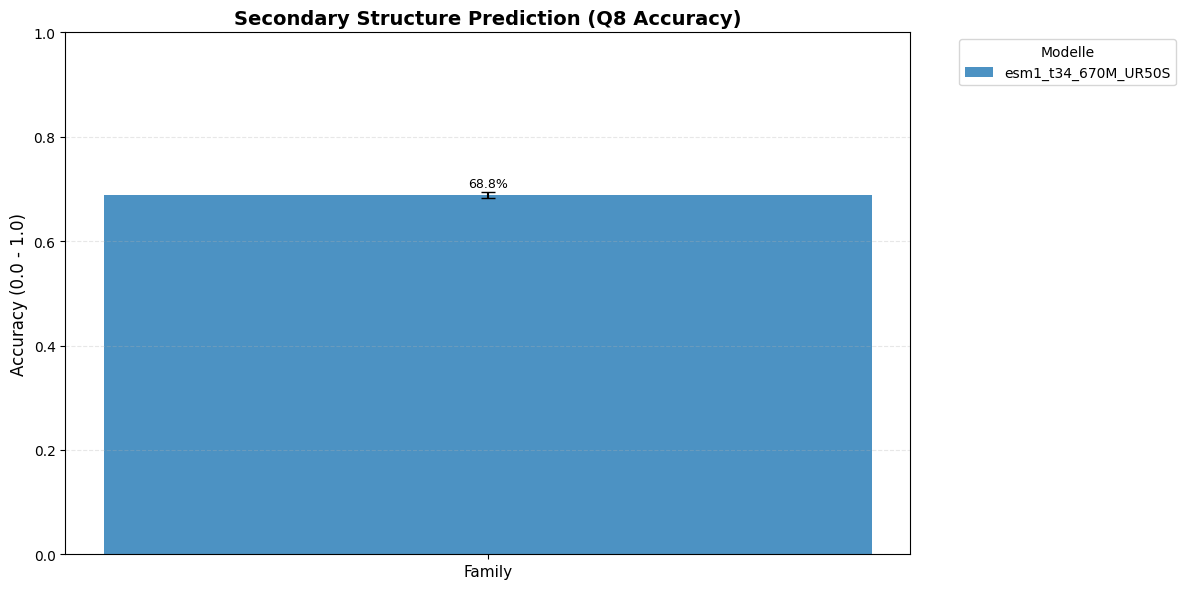

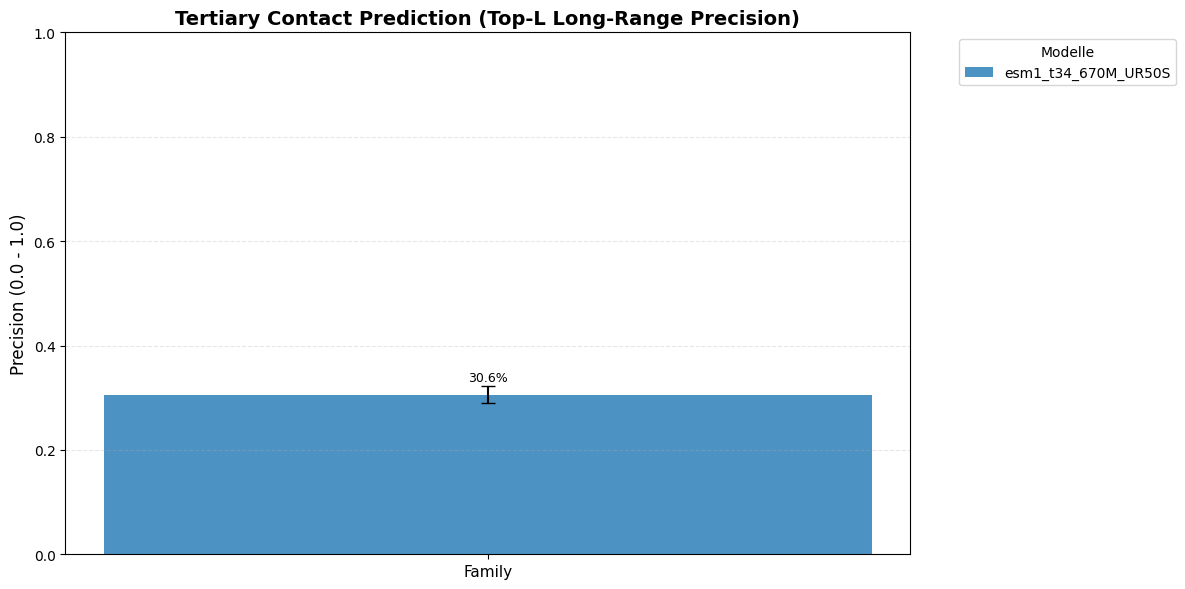

In [11]:
# %% [markdown]
# ## Visualisierung der 5-Fold Cross Validation Ergebnisse
# Erstellt Diagramme mit Mean ± SD für SSP und Kontakte[cite: 2248].

def plot_comprehensive_results(results_dict, title, ylabel):
    """
    Erstellt ein Balkendiagramm für die Ergebnisse über alle Ebenen (Family, Superfamily, Fold).
    """
    # Aktive Level und Modelle aus den Ergebnissen extrahieren
    active_models = [m for m in results_dict.keys() if any(results_dict[m][l] for l in LEVELS)]
    if not active_models:
        print(f"Keine Daten für {title} gefunden.")
        return

    fig, ax = plt.subplots(figsize=(12, 6))
    
    x = np.arange(len(LEVELS))  # Positionen für Family, Superfamily, Fold
    width = 0.8 / len(active_models) # Breite der Balken anpassen
    
    for i, model_name in enumerate(active_models):
        # Berechne Mean und Std für jedes Level über die 5 Partitionen [cite: 2248]
        means = [np.mean(results_dict[model_name][lvl]) if results_dict[model_name][lvl] else 0 for lvl in LEVELS]
        stds = [np.std(results_dict[model_name][lvl]) if results_dict[model_name][lvl] else 0 for lvl in LEVELS]
        
        # Versatz für die Balkengruppen berechnen
        offset = i * width - (len(active_models) * width) / 2 + width/2
        
        # Balken mit Fehlerbalken (yerr) zeichnen
        ax.bar(x + offset, means, width, yerr=stds, label=model_name, capsize=5, alpha=0.8)
        
        # Optionale Text-Labels über den Balken
        for j, val in enumerate(means):
            if val > 0:
                ax.text(j + offset, val + stds[j] + 0.01, f'{val:.1%}', ha='center', fontsize=9)

    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_xticks(x)
    ax.set_xticklabels([l.capitalize() for l in LEVELS], fontsize=11)
    ax.legend(title="Modelle", bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_ylim(0, 1.0) # Skala von 0% bis 100%
    
    plt.tight_layout()
    plt.show()

# Aufruf der Funktionen mit deinen Ergebnis-Dicts
plot_comprehensive_results(ssp_results, "Secondary Structure Prediction (Q8 Accuracy)", "Accuracy (0.0 - 1.0)")
plot_comprehensive_results(contact_results, "Tertiary Contact Prediction (Top-L Long-Range Precision)", "Precision (0.0 - 1.0)")

## Visualization